# CLAM-TR v4: Ablation Study + 5-Fold Cross-Validation

## Goals:
1. **Ablation Study**: Test each proposed improvement INDIVIDUALLY
2. **Find Best Combination**: Only combine changes that actually help
3. **5-Fold CV**: Validate the best model with proper cross-validation
4. **Early Stopping**: Stop training when validation stops improving

## Experiments:
| Experiment | Description |
|------------|-------------|
| baseline | Original CLAM-TR (K=128, dropout=0.25) |
| test_K256 | Only change: K=256 |
| test_ordinal_loss | Only change: Ordinal loss |
| test_fixed_dist | Only change: Fixed distance normalization |
| test_learnable_fusion | Only change: Learnable fusion gate |
| test_dropout_03 | Only change: Dropout 0.3 |
| test_lr_2e4 | Only change: LR 2e-4 |
| test_layernorm | Only change: Extra LayerNorm |

**CRITICAL:** This notebook reuses existing UNI features - NO re-extraction needed!

---
## Section 1: Setup & Installation

In [1]:
!pip install -q scikit-learn pandas matplotlib seaborn tqdm

In [2]:
import os
import json
import time
import random
import copy
from datetime import datetime
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    cohen_kappa_score, accuracy_score, f1_score,
    roc_auc_score, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

print('All imports successful!')

Mounted at /content/drive
All imports successful!


---
## Section 2: Configuration

In [3]:
# ============================================================================
# CONFIGURATION FOR ABLATION STUDY + 5-FOLD CV
# ============================================================================

CONFIG = {
    # Paths (READ-ONLY - shared)
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/',
    'csv_path': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train.csv',
    'original_checkpoints': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',

    # Paths (WRITE - separate folder)
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/v4_ablation/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v4_ablation/',

    # BASELINE parameters (from original working model)
    'feature_dim': 1024,
    'hidden_dim': 512,
    'n_classes': 6,
    'patch_size': 256,
    'num_heads': 8,
    'gamma_values': [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99],

    # BASELINE training (what worked before)
    'baseline_K': 128,
    'baseline_dropout': 0.25,
    'baseline_epochs': 50,
    'baseline_lr': 1e-4,
    'baseline_weight_decay': 1e-5,
    'baseline_label_smoothing': 0.1,

    # Cross-validation
    'n_folds': 5,
    'seed': 42,

    # Early stopping
    'early_stopping_patience': 10,  # Stop if no improvement for 10 epochs
    'early_stopping_min_delta': 0.001,
}

# Set seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])

# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Device: cuda
GPU: Tesla T4


In [4]:
# ============================================================================
# ABLATION EXPERIMENTS - Test each change INDIVIDUALLY
# ============================================================================

ABLATION_EXPERIMENTS = {
    # Baseline (original working model)
    'baseline': {
        'description': 'Original CLAM-TR (baseline)',
        'K': 128,
        'dropout': 0.25,
        'epochs': 50,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': False,
        'ordinal_weight': 0.0,
        'fixed_distance_norm': False,
        'learnable_fusion': False,
        'extra_layernorm': False,
    },

    # Test K=256 only
    'test_K256': {
        'description': 'Only change: K=256 (from ablation study)',
        'K': 256,  # CHANGED
        'dropout': 0.25,
        'epochs': 50,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': False,
        'ordinal_weight': 0.0,
        'fixed_distance_norm': False,
        'learnable_fusion': False,
        'extra_layernorm': False,
    },

    # Test ordinal loss only
    'test_ordinal_loss': {
        'description': 'Only change: Ordinal loss',
        'K': 128,
        'dropout': 0.25,
        'epochs': 50,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': True,  # CHANGED
        'ordinal_weight': 0.3,
        'fixed_distance_norm': False,
        'learnable_fusion': False,
        'extra_layernorm': False,
    },

    # Test fixed distance normalization only
    'test_fixed_dist': {
        'description': 'Only change: Fixed distance normalization',
        'K': 128,
        'dropout': 0.25,
        'epochs': 50,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': False,
        'ordinal_weight': 0.0,
        'fixed_distance_norm': True,  # CHANGED
        'learnable_fusion': False,
        'extra_layernorm': False,
    },

    # Test learnable fusion only
    'test_learnable_fusion': {
        'description': 'Only change: Learnable fusion gate',
        'K': 128,
        'dropout': 0.25,
        'epochs': 50,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': False,
        'ordinal_weight': 0.0,
        'fixed_distance_norm': False,
        'learnable_fusion': True,  # CHANGED
        'extra_layernorm': False,
    },

    # Test higher dropout only
    'test_dropout_03': {
        'description': 'Only change: Dropout 0.3',
        'K': 128,
        'dropout': 0.3,  # CHANGED
        'epochs': 50,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': False,
        'ordinal_weight': 0.0,
        'fixed_distance_norm': False,
        'learnable_fusion': False,
        'extra_layernorm': False,
    },

    # Test higher learning rate only
    'test_lr_2e4': {
        'description': 'Only change: LR 2e-4',
        'K': 128,
        'dropout': 0.25,
        'epochs': 50,
        'lr': 2e-4,  # CHANGED
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': False,
        'ordinal_weight': 0.0,
        'fixed_distance_norm': False,
        'learnable_fusion': False,
        'extra_layernorm': False,
    },

    # Test extra LayerNorm only
    'test_layernorm': {
        'description': 'Only change: Extra LayerNorm in model',
        'K': 128,
        'dropout': 0.25,
        'epochs': 50,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'label_smoothing': 0.1,
        'ordinal_loss': False,
        'ordinal_weight': 0.0,
        'fixed_distance_norm': False,
        'learnable_fusion': False,
        'extra_layernorm': True,  # CHANGED
    },
}

print(f'Defined {len(ABLATION_EXPERIMENTS)} ablation experiments:')
for name, config in ABLATION_EXPERIMENTS.items():
    print(f'  - {name}: {config["description"]}')

Defined 8 ablation experiments:
  - baseline: Original CLAM-TR (baseline)
  - test_K256: Only change: K=256 (from ablation study)
  - test_ordinal_loss: Only change: Ordinal loss
  - test_fixed_dist: Only change: Fixed distance normalization
  - test_learnable_fusion: Only change: Learnable fusion gate
  - test_dropout_03: Only change: Dropout 0.3
  - test_lr_2e4: Only change: LR 2e-4
  - test_layernorm: Only change: Extra LayerNorm in model


In [5]:
# Create directories
os.makedirs(CONFIG['checkpoints_dir'], exist_ok=True)
os.makedirs(CONFIG['results_dir'], exist_ok=True)
os.makedirs(os.path.join(CONFIG['results_dir'], 'models'), exist_ok=True)
os.makedirs(os.path.join(CONFIG['results_dir'], 'visualizations'), exist_ok=True)

print(f'Checkpoints: {CONFIG["checkpoints_dir"]}')
print(f'Results: {CONFIG["results_dir"]}')

Checkpoints: /content/drive/MyDrive/CLAM_TR_Checkpoints/v4_ablation/
Results: /content/drive/MyDrive/CLAM_TR_Results/v4_ablation/


---
## Section 3: Dataset & DataLoader

In [6]:
class PANDAFeatureDataset(Dataset):
    """Dataset that loads pre-extracted features."""
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        data = torch.load(
            os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'),
            map_location='cpu'
        )
        return data['features'], data['coordinates'], self.labels[idx], self.slide_ids[idx]


def collate_fn(batch):
    """Custom collate for single-sample batches."""
    return batch[0][0], batch[0][1], batch[0][2], batch[0][3]


def create_dataloaders(encoder_name='uni', val_ratio=0.2):
    """Create train/val dataloaders using existing features."""
    # Load subset CSV from original checkpoints
    subset_csv = os.path.join(CONFIG['original_checkpoints'], 'subset_600.csv')

    if not os.path.exists(subset_csv):
        print(f'ERROR: Subset CSV not found: {subset_csv}')
        return None, None, None, None

    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['features_dir'], encoder_name)

    if not os.path.exists(features_dir):
        print(f'ERROR: Features directory not found: {features_dir}')
        return None, None, None, None

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    if len(df) < 10:
        print(f'ERROR: Not enough samples ({len(df)})')
        return None, None, None, None

    train_df, val_df = train_test_split(
        df, test_size=val_ratio, stratify=df['isup_grade'], random_state=CONFIG['seed']
    )

    print(f'{encoder_name}: Train={len(train_df)}, Val={len(val_df)}')

    train_ds = PANDAFeatureDataset(
        train_df['image_id'].tolist(),
        train_df['isup_grade'].tolist(),
        features_dir
    )
    val_ds = PANDAFeatureDataset(
        val_df['image_id'].tolist(),
        val_df['isup_grade'].tolist(),
        features_dir
    )

    return (
        DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn),
        DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn),
        train_df,
        val_df
    )


def get_full_dataframe(encoder_name='uni'):
    """Get full dataframe with available features."""
    subset_csv = os.path.join(CONFIG['original_checkpoints'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['features_dir'], encoder_name)
    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
    return df[df['image_id'].isin(available)].reset_index(drop=True), features_dir


print('Dataset functions defined!')

Dataset functions defined!


---
## Section 4: Flexible Model (Supports All Variations)

In [7]:
class SpatialRetentionHead(nn.Module):
    """Spatial retention head with configurable distance normalization."""
    def __init__(self, hidden_dim, gamma=0.9, patch_size=256, fixed_norm=False):
        super().__init__()
        self.gamma = gamma
        self.patch_size = patch_size
        self.fixed_norm = fixed_norm  # Configurable
        self.head_dim = hidden_dim // 8

        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x, coords):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)

        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)

        # Configurable normalization
        if self.fixed_norm:
            # Fixed normalization (not slide-dependent)
            normalized = distances / (self.patch_size * 10)
        else:
            # Original normalization (slide-dependent)
            normalized = distances / (distances.max() + 1e-6)

        D = self.gamma ** normalized
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.head_dim ** 0.5)
        scores = scores * D
        attn = F.softmax(scores, dim=-1)

        return torch.matmul(attn, V)


class SpatialRetention(nn.Module):
    """Multi-head spatial retention."""
    def __init__(self, hidden_dim=512, num_heads=8, gamma_values=None,
                 patch_size=256, fixed_norm=False):
        super().__init__()
        if gamma_values is None:
            gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]

        self.heads = nn.ModuleList([
            SpatialRetentionHead(hidden_dim, gamma_values[i], patch_size, fixed_norm)
            for i in range(num_heads)
        ])
        self.output_proj = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, x, coords):
        out = torch.cat([h(x, coords) for h in self.heads], dim=-1)
        return self.output_proj(out)


print('SpatialRetention defined!')

SpatialRetention defined!


In [8]:
class CLAM_TR_Flexible(nn.Module):
    """
    Flexible CLAM-TR that can toggle each improvement on/off.
    This allows us to test each change individually in ablation study.
    """
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6,
                 dropout=0.25, K=128, num_heads=8, gamma_values=None, patch_size=256,
                 fixed_distance_norm=False, learnable_fusion=False, extra_layernorm=False):
        super().__init__()
        self.K = K
        self.learnable_fusion = learnable_fusion
        self.extra_layernorm = extra_layernorm

        # Feature transform (with optional LayerNorm)
        if extra_layernorm:
            self.feature_transform = nn.Sequential(
                nn.Linear(input_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            )
        else:
            self.feature_transform = nn.Sequential(
                nn.Linear(input_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            )

        # Gated attention (with optional LayerNorm)
        if extra_layernorm:
            self.attention_a = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim // 2),
                nn.LayerNorm(hidden_dim // 2),
                nn.Tanh(),
                nn.Dropout(dropout)
            )
            self.attention_b = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim // 2),
                nn.LayerNorm(hidden_dim // 2),
                nn.Sigmoid(),
                nn.Dropout(dropout)
            )
        else:
            self.attention_a = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim // 2),
                nn.Tanh(),
                nn.Dropout(dropout)
            )
            self.attention_b = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim // 2),
                nn.Sigmoid(),
                nn.Dropout(dropout)
            )
        self.attention_c = nn.Linear(hidden_dim // 2, 1)

        # Spatial retention (with configurable distance norm)
        self.spatial_retention = SpatialRetention(
            hidden_dim, num_heads, gamma_values, patch_size,
            fixed_norm=fixed_distance_norm
        )

        # Fusion (learnable or simple addition)
        if learnable_fusion:
            self.fusion_gate = nn.Sequential(
                nn.Linear(hidden_dim * 2, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout / 2),
                nn.Linear(hidden_dim, 2),
                nn.Softmax(dim=-1)
            )

        # Classifier
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords, return_attention=False):
        h = self.feature_transform(x)

        # Gated attention
        a = self.attention_a(h)
        b = self.attention_b(h)
        A = self.attention_c(a * b).squeeze(-1)
        A_softmax = F.softmax(A, dim=0)

        # Top-K selection
        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices

        h_topk = h[topk_indices]
        coords_topk = coords[topk_indices]
        A_topk = A_softmax[topk_indices]

        # CLAM aggregation
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)

        # Spatial retention
        retention_out = self.spatial_retention(h_topk, coords_topk)
        M_retention = torch.mean(retention_out, dim=0)

        # Fusion
        if self.learnable_fusion:
            fusion_input = torch.cat([M_clam, M_retention], dim=-1)
            weights = self.fusion_gate(fusion_input.unsqueeze(0)).squeeze(0)
            M = weights[0] * M_clam + weights[1] * M_retention
        else:
            M = M_clam + M_retention  # Simple addition (original)

        logits = self.classifier(M)

        if return_attention:
            full_attn = torch.zeros_like(A_softmax)
            full_attn[topk_indices] = A_topk
            return logits, full_attn, topk_indices
        return logits


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print('CLAM_TR_Flexible defined!')

CLAM_TR_Flexible defined!


---
## Section 5: Flexible Loss Function

In [9]:
class FlexibleLoss(nn.Module):
    """
    Loss function that can switch between:
    - Original: Label smoothing only
    - Improved: Label smoothing + Ordinal penalty + Focal weighting
    """
    def __init__(self, n_classes=6, smoothing=0.1, use_ordinal=False, ordinal_weight=0.3):
        super().__init__()
        self.n_classes = n_classes
        self.smoothing = smoothing
        self.use_ordinal = use_ordinal
        self.ordinal_weight = ordinal_weight

    def forward(self, pred, target):
        if pred.dim() == 1:
            pred = pred.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        # Label smoothing CE
        confidence = 1.0 - self.smoothing
        smooth_label = self.smoothing / (self.n_classes - 1)
        one_hot = torch.zeros_like(pred).scatter_(1, target.unsqueeze(1), 1)
        smooth_target = one_hot * confidence + (1 - one_hot) * smooth_label

        log_probs = F.log_softmax(pred, dim=1)
        ce_loss = -(smooth_target * log_probs).sum(dim=1).mean()

        if self.use_ordinal:
            # Add ordinal penalty
            probs = F.softmax(pred, dim=1)
            class_indices = torch.arange(self.n_classes, device=pred.device, dtype=torch.float)
            expected = (probs * class_indices).sum(dim=1)
            ordinal_loss = ((expected - target.float()) ** 2).mean()
            return ce_loss + self.ordinal_weight * ordinal_loss

        return ce_loss


print('FlexibleLoss defined!')

FlexibleLoss defined!


---
## Section 6: Early Stopping

In [10]:
class EarlyStopping:
    """Stop training when validation metric stops improving."""
    def __init__(self, patience=10, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_score = None
        self.should_stop = False

    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False

        if score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
                return True
        return False

    def reset(self):
        self.counter = 0
        self.best_score = None
        self.should_stop = False


print('EarlyStopping defined!')

EarlyStopping defined!


---
## Section 7: Training Function

In [11]:
def train_experiment(exp_name, exp_config, train_loader, val_loader, device, verbose=True):
    """
    Train a single experiment configuration.

    Args:
        exp_name: Experiment name
        exp_config: Dictionary with experiment configuration
        train_loader: Training data loader
        val_loader: Validation data loader
        device: Device to train on
        verbose: Print progress

    Returns:
        metrics: Dictionary with final metrics
        best_model_state: Best model state dict
    """

    if verbose:
        print(f'\n{"-"*60}')
        print(f'Experiment: {exp_name}')
        print(f'Description: {exp_config["description"]}')
        print(f'{"-"*60}')

    # Create model
    model = CLAM_TR_Flexible(
        input_dim=CONFIG['feature_dim'],
        hidden_dim=CONFIG['hidden_dim'],
        n_classes=CONFIG['n_classes'],
        dropout=exp_config['dropout'],
        K=exp_config['K'],
        num_heads=CONFIG['num_heads'],
        gamma_values=CONFIG['gamma_values'],
        patch_size=CONFIG['patch_size'],
        fixed_distance_norm=exp_config['fixed_distance_norm'],
        learnable_fusion=exp_config['learnable_fusion'],
        extra_layernorm=exp_config['extra_layernorm']
    ).to(device)

    if verbose:
        print(f'Model parameters: {count_parameters(model):,}')

    # Create loss
    criterion = FlexibleLoss(
        n_classes=CONFIG['n_classes'],
        smoothing=exp_config['label_smoothing'],
        use_ordinal=exp_config['ordinal_loss'],
        ordinal_weight=exp_config.get('ordinal_weight', 0.3)
    )

    optimizer = Adam(
        model.parameters(),
        lr=exp_config['lr'],
        weight_decay=exp_config['weight_decay']
    )
    scheduler = CosineAnnealingLR(optimizer, T_max=exp_config['epochs'])
    early_stopping = EarlyStopping(
        patience=CONFIG['early_stopping_patience'],
        min_delta=CONFIG['early_stopping_min_delta']
    )

    best_qwk = -1
    best_model_state = None
    history = {'train_loss': [], 'val_qwk': [], 'val_acc': []}

    for epoch in range(exp_config['epochs']):
        # Train
        model.train()
        train_loss = 0
        for features, coords, label, _ in train_loader:
            features, coords = features.to(device), coords.to(device)
            label = torch.tensor(label).to(device)

            optimizer.zero_grad()
            logits = model(features, coords)
            loss = criterion(logits, label)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item()

        train_loss /= len(train_loader)

        # Validate
        model.eval()
        preds, labels = [], []
        with torch.no_grad():
            for features, coords, label, _ in val_loader:
                features, coords = features.to(device), coords.to(device)
                logits = model(features, coords)
                preds.append(logits.argmax().cpu().item())
                labels.append(label)

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')
        acc = accuracy_score(labels, preds)

        history['train_loss'].append(train_loss)
        history['val_qwk'].append(qwk)
        history['val_acc'].append(acc)

        scheduler.step()

        # Save best
        if qwk > best_qwk:
            best_qwk = qwk
            best_model_state = copy.deepcopy(model.state_dict())
            if verbose:
                print(f'Epoch {epoch+1:3d}: QWK={qwk:.4f}*, Acc={acc:.4f}')
        elif verbose and (epoch + 1) % 10 == 0:
            print(f'Epoch {epoch+1:3d}: QWK={qwk:.4f}, Acc={acc:.4f}')

        # Early stopping
        if early_stopping(qwk):
            if verbose:
                print(f'Early stopping at epoch {epoch+1}')
            break

    # Load best model and get final metrics
    model.load_state_dict(best_model_state)
    model.eval()

    preds, labels, probs = [], [], []
    with torch.no_grad():
        for features, coords, label, _ in val_loader:
            features, coords = features.to(device), coords.to(device)
            logits = model(features, coords)
            preds.append(logits.argmax().cpu().item())
            labels.append(label)
            probs.append(F.softmax(logits, dim=0).cpu().numpy())

    final_metrics = {
        'qwk': cohen_kappa_score(labels, preds, weights='quadratic'),
        'accuracy': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
        'per_class_f1': f1_score(labels, preds, average=None).tolist(),
        'confusion_matrix': confusion_matrix(labels, preds).tolist(),
        'best_epoch': len(history['val_qwk']) - early_stopping.counter,
        'total_epochs': len(history['val_qwk']),
        'history': history
    }

    if verbose:
        print(f'Final: QWK={final_metrics["qwk"]:.4f}, Acc={final_metrics["accuracy"]:.4f}')

    # Cleanup
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return final_metrics, best_model_state


print('train_experiment function defined!')

train_experiment function defined!


---
## Section 8: Ablation Study Runner

In [12]:
def run_ablation_study():
    """Run all ablation experiments and compare results."""

    print('='*70)
    print('ABLATION STUDY: Testing each improvement individually')
    print('='*70)

    # Create single train/val split for ablation (consistent comparison)
    train_loader, val_loader, _, _ = create_dataloaders('uni')

    if train_loader is None:
        print('ERROR: Features not found!')
        return None

    results = {}

    # Check for existing results
    results_file = os.path.join(CONFIG['results_dir'], 'ablation_results.json')
    if os.path.exists(results_file):
        with open(results_file, 'r') as f:
            results = json.load(f)
        print(f'Loaded {len(results)} existing results')

    for exp_name, exp_config in ABLATION_EXPERIMENTS.items():
        # Skip if already done
        if exp_name in results:
            print(f'\nSkipping {exp_name} (already completed)')
            continue

        metrics, model_state = train_experiment(
            exp_name, exp_config, train_loader, val_loader, DEVICE
        )
        results[exp_name] = metrics

        # Save model
        torch.save(
            model_state,
            os.path.join(CONFIG['results_dir'], 'models', f'{exp_name}.pt')
        )

        # Save intermediate results
        with open(results_file, 'w') as f:
            json.dump(results, f, indent=2)

    # Print comparison table
    print('\n' + '='*90)
    print('ABLATION STUDY RESULTS')
    print('='*90)
    print(f'{"Experiment":<25} {"QWK":>10} {"Accuracy":>10} {"Macro F1":>10} {"Best Epoch":>12} {"Status":>8}')
    print('-'*90)

    baseline_qwk = results['baseline']['qwk']

    for name, metrics in results.items():
        qwk_diff = metrics['qwk'] - baseline_qwk
        if qwk_diff > 0.005:
            marker = '+'
        elif qwk_diff < -0.005:
            marker = '-'
        else:
            marker = '~'
        print(f'{name:<25} {metrics["qwk"]:>10.4f} {metrics["accuracy"]:>10.4f} {metrics["macro_f1"]:>10.4f} {metrics["best_epoch"]:>12} {marker:>8}')

    print('='*90)
    print('+ = Improved (>0.5%), - = Worse (<-0.5%), ~ = Similar')

    return results


print('run_ablation_study function defined!')

run_ablation_study function defined!


---
## Section 9: 5-Fold Cross-Validation

In [13]:
def run_cross_validation(config_name, config):
    """
    Run 5-fold CV on a given configuration.

    Args:
        config_name: Name of the configuration
        config: Configuration dictionary

    Returns:
        cv_results: Dictionary with CV results
    """

    print('\n' + '='*70)
    print(f'5-FOLD CROSS-VALIDATION: {config_name}')
    print(f'Description: {config["description"]}')
    print('='*70)

    # Load data
    df, features_dir = get_full_dataframe('uni')

    if len(df) == 0:
        print('ERROR: No data available!')
        return None

    print(f'Total samples: {len(df)}')

    skf = StratifiedKFold(
        n_splits=CONFIG['n_folds'],
        shuffle=True,
        random_state=CONFIG['seed']
    )

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        print(f'\n--- Fold {fold+1}/{CONFIG["n_folds"]} ---')

        train_df = df.iloc[train_idx]
        val_df = df.iloc[val_idx]

        train_ds = PANDAFeatureDataset(
            train_df['image_id'].tolist(),
            train_df['isup_grade'].tolist(),
            features_dir
        )
        val_ds = PANDAFeatureDataset(
            val_df['image_id'].tolist(),
            val_df['isup_grade'].tolist(),
            features_dir
        )

        train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

        print(f'Train: {len(train_df)}, Val: {len(val_df)}')

        metrics, model_state = train_experiment(
            f'{config_name}_fold{fold+1}',
            config,
            train_loader,
            val_loader,
            DEVICE,
            verbose=True
        )

        fold_results.append(metrics)

        # Save fold model
        torch.save(
            model_state,
            os.path.join(CONFIG['results_dir'], 'models', f'{config_name}_fold{fold+1}.pt')
        )

    # Compute mean and std
    qwk_scores = [r['qwk'] for r in fold_results]
    acc_scores = [r['accuracy'] for r in fold_results]
    f1_scores = [r['macro_f1'] for r in fold_results]

    cv_results = {
        'config_name': config_name,
        'config': config,
        'fold_results': fold_results,
        'qwk_scores': qwk_scores,
        'acc_scores': acc_scores,
        'f1_scores': f1_scores,
        'mean_qwk': float(np.mean(qwk_scores)),
        'std_qwk': float(np.std(qwk_scores)),
        'mean_accuracy': float(np.mean(acc_scores)),
        'std_accuracy': float(np.std(acc_scores)),
        'mean_f1': float(np.mean(f1_scores)),
        'std_f1': float(np.std(f1_scores)),
    }

    # Print results
    print('\n' + '='*70)
    print(f'5-FOLD CV RESULTS: {config_name}')
    print('='*70)
    print(f'\nFold Results:')
    for i, r in enumerate(fold_results):
        print(f'  Fold {i+1}: QWK={r["qwk"]:.4f}, Acc={r["accuracy"]:.4f}, F1={r["macro_f1"]:.4f}')

    print(f'\nFinal Results (mean +/- std):')
    print(f'  QWK:      {cv_results["mean_qwk"]:.4f} +/- {cv_results["std_qwk"]:.4f}')
    print(f'  Accuracy: {cv_results["mean_accuracy"]:.4f} +/- {cv_results["std_accuracy"]:.4f}')
    print(f'  Macro F1: {cv_results["mean_f1"]:.4f} +/- {cv_results["std_f1"]:.4f}')
    print('='*70)

    # Save results
    cv_file = os.path.join(CONFIG['results_dir'], f'cv_results_{config_name}.json')
    with open(cv_file, 'w') as f:
        # Convert config to serializable format
        save_results = cv_results.copy()
        save_results['config'] = {k: str(v) if not isinstance(v, (int, float, bool, str, list)) else v
                                   for k, v in config.items()}
        json.dump(save_results, f, indent=2)

    return cv_results


print('run_cross_validation function defined!')

run_cross_validation function defined!


---
## Section 10: Visualization Functions

In [14]:
def plot_ablation_results(results):
    """Plot ablation study results as bar chart."""

    names = list(results.keys())
    qwk_scores = [results[n]['qwk'] for n in names]
    acc_scores = [results[n]['accuracy'] for n in names]

    baseline_qwk = results['baseline']['qwk']

    # Color bars based on improvement
    colors = []
    for n in names:
        diff = results[n]['qwk'] - baseline_qwk
        if n == 'baseline':
            colors.append('gray')
        elif diff > 0.005:
            colors.append('green')
        elif diff < -0.005:
            colors.append('red')
        else:
            colors.append('orange')

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # QWK plot
    axes[0].barh(names, qwk_scores, color=colors)
    axes[0].axvline(x=baseline_qwk, color='black', linestyle='--', label='Baseline')
    axes[0].set_xlabel('Quadratic Weighted Kappa')
    axes[0].set_title('Ablation Study: QWK Comparison')
    axes[0].legend()

    # Accuracy plot
    axes[1].barh(names, acc_scores, color=colors)
    axes[1].axvline(x=results['baseline']['accuracy'], color='black', linestyle='--', label='Baseline')
    axes[1].set_xlabel('Accuracy')
    axes[1].set_title('Ablation Study: Accuracy Comparison')
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(
        os.path.join(CONFIG['results_dir'], 'visualizations', 'ablation_results.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.show()


def plot_cv_comparison(cv_baseline, cv_best):
    """Plot CV comparison between baseline and best model."""

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(3)
    width = 0.35

    baseline_means = [cv_baseline['mean_qwk'], cv_baseline['mean_accuracy'], cv_baseline['mean_f1']]
    baseline_stds = [cv_baseline['std_qwk'], cv_baseline['std_accuracy'], cv_baseline['std_f1']]

    best_means = [cv_best['mean_qwk'], cv_best['mean_accuracy'], cv_best['mean_f1']]
    best_stds = [cv_best['std_qwk'], cv_best['std_accuracy'], cv_best['std_f1']]

    bars1 = ax.bar(x - width/2, baseline_means, width, yerr=baseline_stds,
                   label='Baseline', capsize=5, color='steelblue')
    bars2 = ax.bar(x + width/2, best_means, width, yerr=best_stds,
                   label='Best Combination', capsize=5, color='forestgreen')

    ax.set_ylabel('Score')
    ax.set_title('5-Fold Cross-Validation: Baseline vs Best Combination')
    ax.set_xticks(x)
    ax.set_xticklabels(['QWK', 'Accuracy', 'Macro F1'])
    ax.legend()
    ax.set_ylim(0, 1)

    # Add value labels
    for bar, mean, std in zip(bars1, baseline_means, baseline_stds):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.02,
                f'{mean:.3f}', ha='center', va='bottom', fontsize=9)
    for bar, mean, std in zip(bars2, best_means, best_stds):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.02,
                f'{mean:.3f}', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.savefig(
        os.path.join(CONFIG['results_dir'], 'visualizations', 'cv_comparison.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.show()


print('Visualization functions defined!')

Visualization functions defined!


---
## Section 11: Verify Features

In [15]:
# ============================================================================
# VERIFY FEATURES BEFORE RUNNING
# ============================================================================

print('='*60)
print('VERIFYING UNI FEATURES')
print('='*60)

uni_dir = os.path.join(CONFIG['features_dir'], 'uni')

if os.path.exists(uni_dir):
    n_features = len([f for f in os.listdir(uni_dir) if f.endswith('.pt')])
    print(f'UNI features found: {n_features}/600')

    if n_features >= 600:
        print('\nREADY TO RUN ABLATION STUDY!')

        # Check sample
        sample = [f for f in os.listdir(uni_dir) if f.endswith('.pt')][0]
        data = torch.load(os.path.join(uni_dir, sample), map_location='cpu')
        print(f'\nSample: {sample}')
        print(f'  Features: {data["features"].shape}')
        print(f'  Coords: {data["coordinates"].shape}')
    else:
        print(f'\nWARNING: Only {n_features}/600 features found')
else:
    print(f'ERROR: UNI features not found at {uni_dir}')

print('='*60)

VERIFYING UNI FEATURES
UNI features found: 600/600

READY TO RUN ABLATION STUDY!

Sample: 6b69560eba8205a182f996d752402036.pt
  Features: torch.Size([355, 1024])
  Coords: torch.Size([355, 2])


---
## Section 12: Run Ablation Study

In [16]:
# ============================================================================
# STEP 1: RUN ABLATION STUDY
# ============================================================================
# This tests each improvement individually to see what actually helps
# Expected time: ~12 hours (8 experiments x ~1.5h each)
# ============================================================================

print('\n' + '='*70)
print('STEP 1: ABLATION STUDY')
print('Testing each improvement individually...')
print('='*70)

ablation_results = run_ablation_study()


STEP 1: ABLATION STUDY
Testing each improvement individually...
ABLATION STUDY: Testing each improvement individually
uni: Train=480, Val=120

------------------------------------------------------------
Experiment: baseline
Description: Original CLAM-TR (baseline)
------------------------------------------------------------
Model parameters: 1,839,879
Epoch   1: QWK=0.7917*, Acc=0.5583
Epoch   7: QWK=0.8099*, Acc=0.5417
Epoch  10: QWK=0.7766, Acc=0.5417
Epoch  14: QWK=0.8268*, Acc=0.6083
Epoch  20: QWK=0.7577, Acc=0.5083
Early stopping at epoch 24
Final: QWK=0.8268, Acc=0.6083

------------------------------------------------------------
Experiment: test_K256
Description: Only change: K=256 (from ablation study)
------------------------------------------------------------
Model parameters: 1,839,879
Epoch   1: QWK=0.7448*, Acc=0.5417
Epoch   3: QWK=0.7830*, Acc=0.5917
Epoch   9: QWK=0.7861*, Acc=0.6000
Epoch  10: QWK=0.7731, Acc=0.6167
Epoch  13: QWK=0.8035*, Acc=0.6417
Epoch  20: QW

---
## Section 13: Analyze Results & Create Best Config

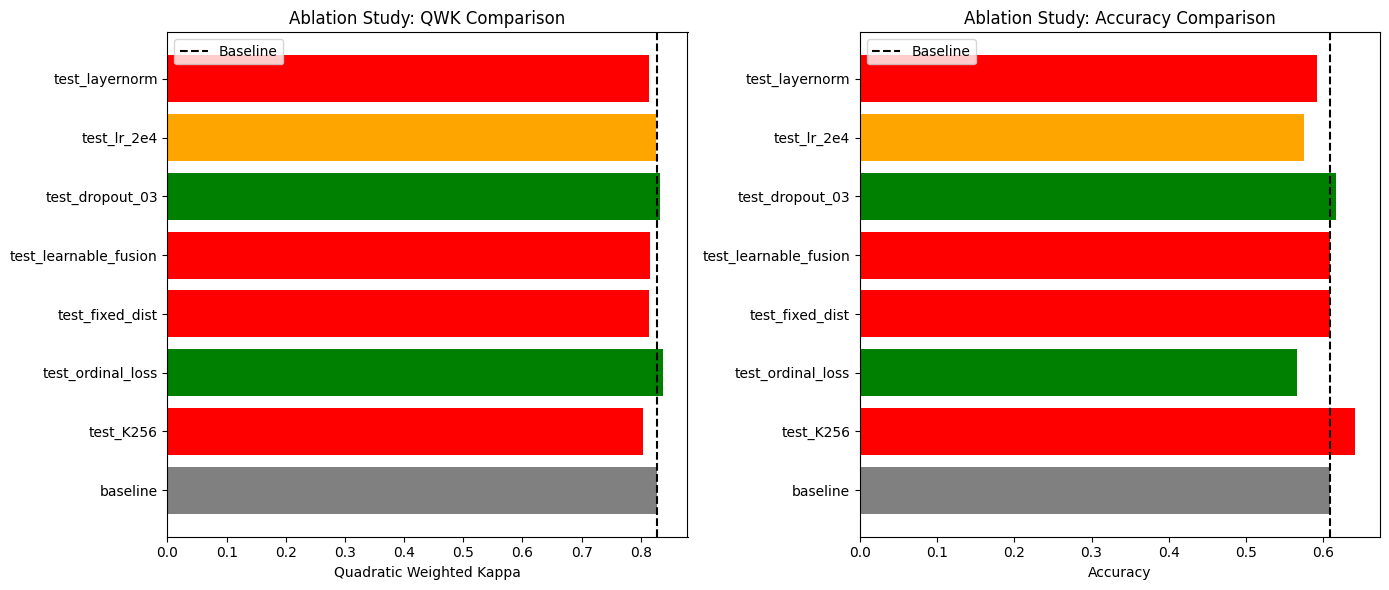


IMPROVEMENT ANALYSIS
Baseline QWK: 0.8268

Individual changes:
  test_ordinal_loss        : +0.0104 (HELPED)
  test_dropout_03          : +0.0051 (HELPED)
  test_lr_2e4              : -0.0018 (NO CHANGE)
  test_learnable_fusion    : -0.0106 (HURT)
  test_layernorm           : -0.0123 (HURT)
  test_fixed_dist          : -0.0132 (HURT)
  test_K256                : -0.0233 (HURT)

CREATING BEST CONFIGURATION
  + Adding ordinal loss
  + Adding dropout 0.3

Best config: Best: ordinal_loss + dropout=0.3


In [17]:
# ============================================================================
# ANALYZE ABLATION RESULTS & CREATE BEST CONFIGURATION
# ============================================================================

if ablation_results:
    # Plot ablation results
    plot_ablation_results(ablation_results)

    # Find which changes helped
    baseline_qwk = ablation_results['baseline']['qwk']
    improvements = {}

    for name, metrics in ablation_results.items():
        if name != 'baseline':
            diff = metrics['qwk'] - baseline_qwk
            improvements[name] = diff

    print('\n' + '='*70)
    print('IMPROVEMENT ANALYSIS')
    print('='*70)
    print(f'Baseline QWK: {baseline_qwk:.4f}')
    print('\nIndividual changes:')
    for name, diff in sorted(improvements.items(), key=lambda x: x[1], reverse=True):
        if diff > 0.005:
            status = 'HELPED'
        elif diff < -0.005:
            status = 'HURT'
        else:
            status = 'NO CHANGE'
        print(f'  {name:<25}: {diff:+.4f} ({status})')

    # Create best config by combining improvements that helped
    best_config = copy.deepcopy(ABLATION_EXPERIMENTS['baseline'])
    best_config['description'] = 'Best combination of improvements'

    print('\n' + '='*70)
    print('CREATING BEST CONFIGURATION')
    print('='*70)

    changes_made = []

    if improvements.get('test_K256', 0) > 0.005:
        best_config['K'] = 256
        changes_made.append('K=256')
        print('  + Adding K=256')

    if improvements.get('test_ordinal_loss', 0) > 0.005:
        best_config['ordinal_loss'] = True
        best_config['ordinal_weight'] = 0.3
        changes_made.append('ordinal_loss')
        print('  + Adding ordinal loss')

    if improvements.get('test_fixed_dist', 0) > 0.005:
        best_config['fixed_distance_norm'] = True
        changes_made.append('fixed_distance_norm')
        print('  + Adding fixed distance normalization')

    if improvements.get('test_learnable_fusion', 0) > 0.005:
        best_config['learnable_fusion'] = True
        changes_made.append('learnable_fusion')
        print('  + Adding learnable fusion')

    if improvements.get('test_dropout_03', 0) > 0.005:
        best_config['dropout'] = 0.3
        changes_made.append('dropout=0.3')
        print('  + Adding dropout 0.3')

    if improvements.get('test_lr_2e4', 0) > 0.005:
        best_config['lr'] = 2e-4
        changes_made.append('lr=2e-4')
        print('  + Adding LR 2e-4')

    if improvements.get('test_layernorm', 0) > 0.005:
        best_config['extra_layernorm'] = True
        changes_made.append('extra_layernorm')
        print('  + Adding extra LayerNorm')

    if len(changes_made) == 0:
        print('  No improvements found - using baseline')
        best_config['description'] = 'Baseline (no improvements helped)'
    else:
        best_config['description'] = f'Best: {" + ".join(changes_made)}'

    print('\n' + '='*70)
    print(f'Best config: {best_config["description"]}')
    print('='*70)
else:
    print('No ablation results available!')
    best_config = None

---
## Section 14: Run 5-Fold Cross-Validation

In [18]:
# ============================================================================
# STEP 2: 5-FOLD CROSS-VALIDATION
# ============================================================================
# Run CV on both baseline and best configuration for fair comparison
# Expected time: ~15 hours (2 configs x 5 folds x ~1.5h each)
# ============================================================================

if best_config:
    print('\n' + '='*70)
    print('STEP 2: 5-FOLD CROSS-VALIDATION')
    print('='*70)

    # Run CV on best config
    print('\nRunning CV on best configuration...')
    cv_best = run_cross_validation('best_combination', best_config)

    # Run CV on baseline for comparison
    print('\nRunning CV on baseline for comparison...')
    cv_baseline = run_cross_validation('baseline', ABLATION_EXPERIMENTS['baseline'])
else:
    print('No best config available - run ablation study first!')
    cv_best = None
    cv_baseline = None


STEP 2: 5-FOLD CROSS-VALIDATION

Running CV on best configuration...

5-FOLD CROSS-VALIDATION: best_combination
Description: Best: ordinal_loss + dropout=0.3
Total samples: 600

--- Fold 1/5 ---
Train: 480, Val: 120

------------------------------------------------------------
Experiment: best_combination_fold1
Description: Best: ordinal_loss + dropout=0.3
------------------------------------------------------------
Model parameters: 1,839,879
Epoch   1: QWK=0.7855*, Acc=0.5417
Epoch   3: QWK=0.7979*, Acc=0.5833
Epoch   4: QWK=0.8104*, Acc=0.6333
Epoch   9: QWK=0.8240*, Acc=0.6167
Epoch  10: QWK=0.8365*, Acc=0.6083
Epoch  20: QWK=0.8186, Acc=0.6083
Early stopping at epoch 20
Final: QWK=0.8365, Acc=0.6083

--- Fold 2/5 ---
Train: 480, Val: 120

------------------------------------------------------------
Experiment: best_combination_fold2
Description: Best: ordinal_loss + dropout=0.3
------------------------------------------------------------
Model parameters: 1,839,879
Epoch   1: QWK

---
## Section 15: Final Results & Comparison

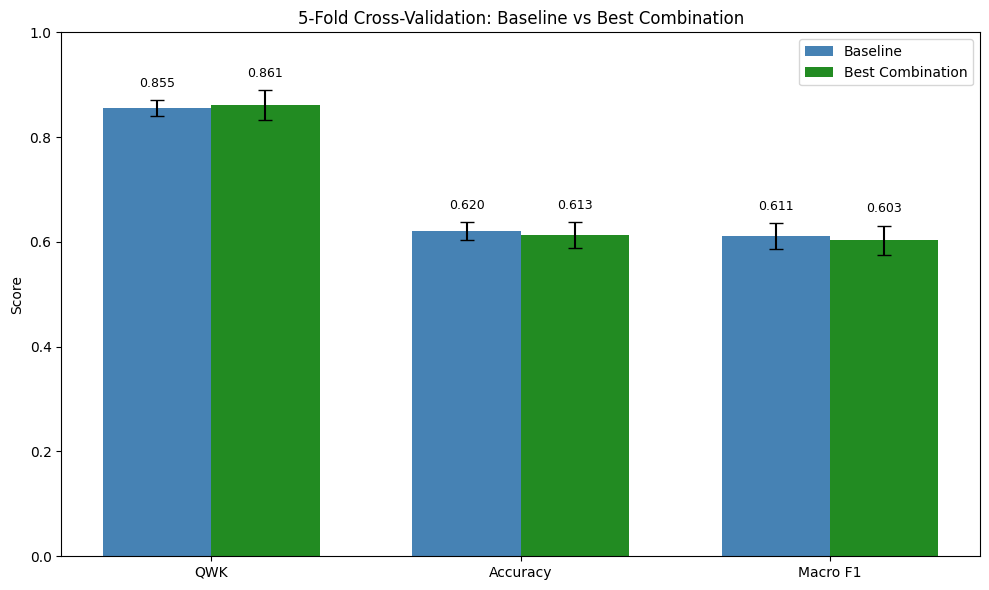


FINAL COMPARISON (5-Fold Cross-Validation)

Model                     QWK                       Accuracy                  Macro F1                 
--------------------------------------------------------------------------------
Baseline                  0.8553 +/- 0.0154      0.6200 +/- 0.0172      0.6106 +/- 0.0246
Best Combination          0.8610 +/- 0.0280      0.6133 +/- 0.0245      0.6028 +/- 0.0276

Improvement over baseline:
  QWK:      +0.0057 (+0.66%)
  Accuracy: -0.0067 (-1.08%)

Statistical significance (paired t-test):
  t-statistic: 0.8970
  p-value: 0.4204
  Result: Not statistically significant (p >= 0.05)

Results saved to: /content/drive/MyDrive/CLAM_TR_Results/v4_ablation/


In [19]:
# ============================================================================
# FINAL RESULTS & COMPARISON
# ============================================================================

if cv_best and cv_baseline:
    # Plot comparison
    plot_cv_comparison(cv_baseline, cv_best)

    # Print final comparison
    print('\n' + '='*80)
    print('FINAL COMPARISON (5-Fold Cross-Validation)')
    print('='*80)
    print(f'\n{"Model":<25} {"QWK":<25} {"Accuracy":<25} {"Macro F1":<25}')
    print('-'*80)
    print(f'{"Baseline":<25} {cv_baseline["mean_qwk"]:.4f} +/- {cv_baseline["std_qwk"]:.4f}      {cv_baseline["mean_accuracy"]:.4f} +/- {cv_baseline["std_accuracy"]:.4f}      {cv_baseline["mean_f1"]:.4f} +/- {cv_baseline["std_f1"]:.4f}')
    print(f'{"Best Combination":<25} {cv_best["mean_qwk"]:.4f} +/- {cv_best["std_qwk"]:.4f}      {cv_best["mean_accuracy"]:.4f} +/- {cv_best["std_accuracy"]:.4f}      {cv_best["mean_f1"]:.4f} +/- {cv_best["std_f1"]:.4f}')
    print('='*80)

    # Calculate improvement
    qwk_improvement = cv_best['mean_qwk'] - cv_baseline['mean_qwk']
    acc_improvement = cv_best['mean_accuracy'] - cv_baseline['mean_accuracy']

    print(f'\nImprovement over baseline:')
    print(f'  QWK:      {qwk_improvement:+.4f} ({qwk_improvement/cv_baseline["mean_qwk"]*100:+.2f}%)')
    print(f'  Accuracy: {acc_improvement:+.4f} ({acc_improvement/cv_baseline["mean_accuracy"]*100:+.2f}%)')

    # Statistical significance (simple comparison)
    from scipy import stats
    try:
        t_stat, p_value = stats.ttest_rel(cv_best['qwk_scores'], cv_baseline['qwk_scores'])
        print(f'\nStatistical significance (paired t-test):')
        print(f'  t-statistic: {t_stat:.4f}')
        print(f'  p-value: {p_value:.4f}')
        if p_value < 0.05:
            print('  Result: STATISTICALLY SIGNIFICANT (p < 0.05)')
        else:
            print('  Result: Not statistically significant (p >= 0.05)')
    except:
        print('\nCould not compute statistical significance')

    print('='*80)

    # Save final summary
    final_summary = {
        'baseline': {
            'mean_qwk': cv_baseline['mean_qwk'],
            'std_qwk': cv_baseline['std_qwk'],
            'mean_accuracy': cv_baseline['mean_accuracy'],
            'std_accuracy': cv_baseline['std_accuracy'],
        },
        'best_combination': {
            'config': best_config['description'],
            'mean_qwk': cv_best['mean_qwk'],
            'std_qwk': cv_best['std_qwk'],
            'mean_accuracy': cv_best['mean_accuracy'],
            'std_accuracy': cv_best['std_accuracy'],
        },
        'improvement': {
            'qwk': qwk_improvement,
            'accuracy': acc_improvement,
        }
    }

    with open(os.path.join(CONFIG['results_dir'], 'final_summary.json'), 'w') as f:
        json.dump(final_summary, f, indent=2)

    print(f'\nResults saved to: {CONFIG["results_dir"]}')
else:
    print('Cross-validation results not available!')

In [20]:
# ============================================================================
# CONCLUSION
# ============================================================================

print('\n' + '='*80)
print('ABLATION STUDY + 5-FOLD CV COMPLETE!')
print('='*80)

print(f'''\nFiles saved:
  Ablation results:    {CONFIG['results_dir']}/ablation_results.json
  CV results baseline: {CONFIG['results_dir']}/cv_results_baseline.json
  CV results best:     {CONFIG['results_dir']}/cv_results_best_combination.json
  Final summary:       {CONFIG['results_dir']}/final_summary.json
  Models:              {CONFIG['results_dir']}/models/
  Visualizations:      {CONFIG['results_dir']}/visualizations/
''')

print('='*80)


ABLATION STUDY + 5-FOLD CV COMPLETE!

Files saved:
  Ablation results:    /content/drive/MyDrive/CLAM_TR_Results/v4_ablation//ablation_results.json
  CV results baseline: /content/drive/MyDrive/CLAM_TR_Results/v4_ablation//cv_results_baseline.json
  CV results best:     /content/drive/MyDrive/CLAM_TR_Results/v4_ablation//cv_results_best_combination.json
  Final summary:       /content/drive/MyDrive/CLAM_TR_Results/v4_ablation//final_summary.json
  Models:              /content/drive/MyDrive/CLAM_TR_Results/v4_ablation//models/
  Visualizations:      /content/drive/MyDrive/CLAM_TR_Results/v4_ablation//visualizations/

